## **1. Import Libraries**


We're grouping imports by purpose: data handling, visualization, preprocessing, models, evaluation, and saving. Keeping imports grouped like this makes it easy to see at a glance what the notebook is going to do.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


# **2. Load the Dataset**

We load the CSV and take a first look at its shape and the first few rows. This is always the very first step — you can't make any decisions about a dataset until you've actually looked at it.


In [2]:
df= pd.read_csv("Student Social Media And Mental Health Impact.csv")
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [3]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [4]:
df.isnull().sum()

,0
Age,0
Gender,0
Country,0
Academic_Level,0
Most_Used_Platform,0
Purpose_Of_Use,0
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,0
Physical_Activity_Hours,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB



📌 Reading this: Most columns look reasonable — but look closely at Physical_Activity_Hours: the minimum value is -0.4. Negative hours aren't physically possible, so this is a data-entry glitch, not a real value. We'll fix this properly in the Data Cleaning step below instead of ignoring it.

## 4. Exploratory Data Analysis (EDA)

We'll keep this focused — six plots, each answering one specific question about the data, not a wall of charts for the sake of it.

## 4.1 — Distribution of the target (Mental_Health_Score)

Before predicting anything, we need to understand the shape of what we're predicting.

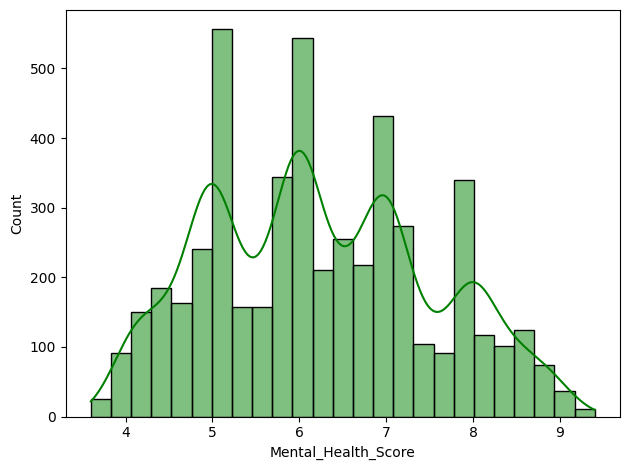

In [6]:
sns.histplot(df["Mental_Health_Score"],color="green",kde=True)
plt.tight_layout()
plt.show()

## 4.2 — Correlation **heatmap**

## Which numeric features actually move together with the target?


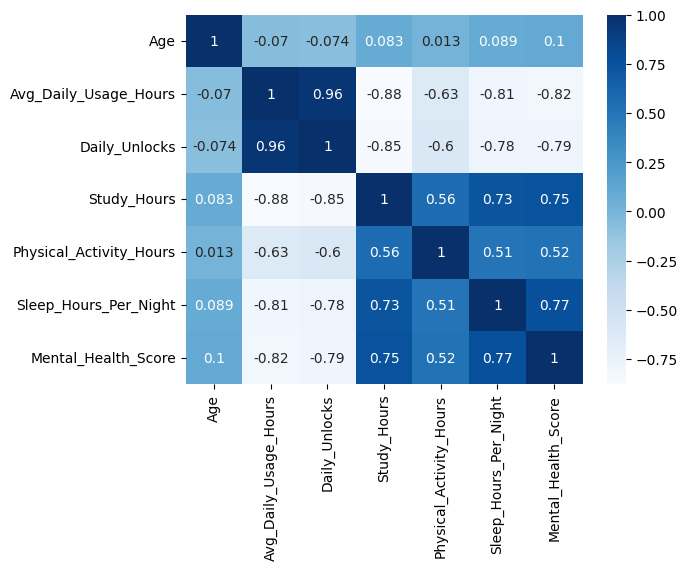

In [7]:
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="Blues")
plt.show()

## **4.3 — Stress Level vs Mental Health Score**
# Does higher stress genuinely come with a lower score?

In [8]:
df['Stress_Level'].unique()
order=['Low','Medium' , 'High', 'Very High']

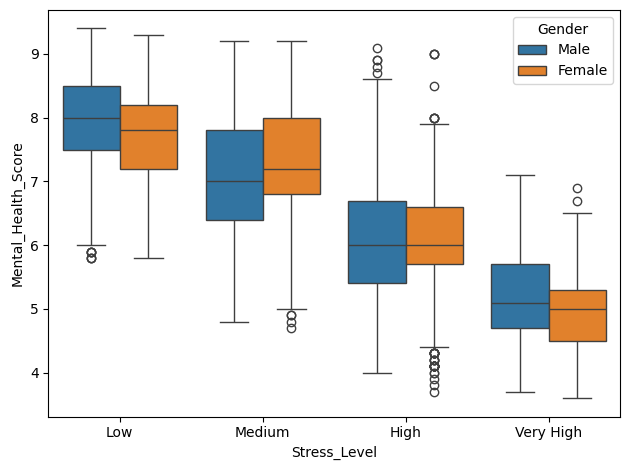

In [9]:
sns.boxplot(x=df['Stress_Level'], y= df['Mental_Health_Score'],order = order, hue=df['Gender'])
plt.tight_layout()
plt.show()

## **4.4 — Daily Usage Hours vs Mental Health Score**
Does more time on social media relate to a lower score for diffrent age groups
?

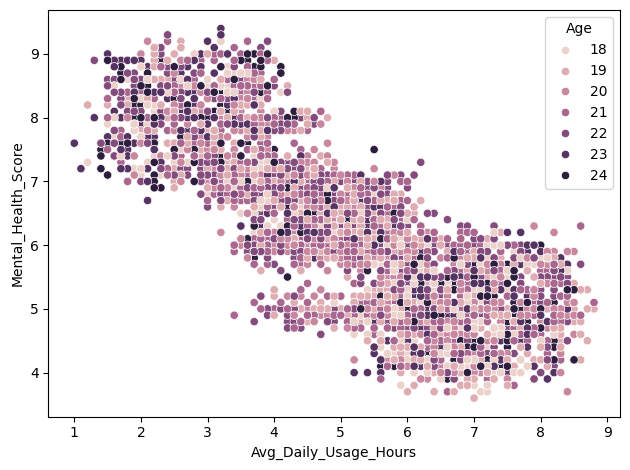

In [10]:
sns.scatterplot(x=df['Avg_Daily_Usage_Hours'] , y = df['Mental_Health_Score'], hue = df['Age'])
plt.tight_layout()
plt.show()

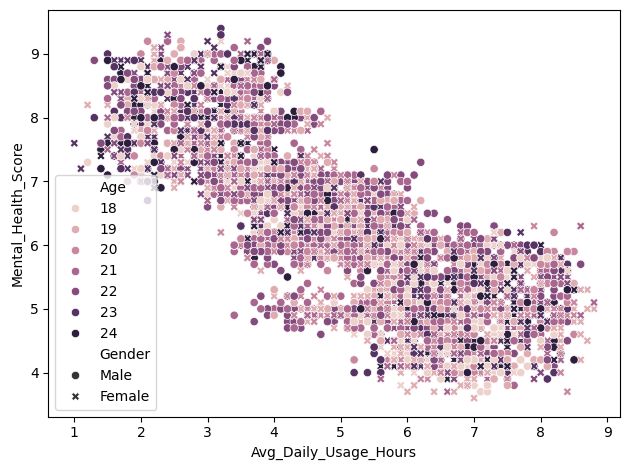

In [11]:
sns.scatterplot(x=df['Avg_Daily_Usage_Hours'], y=df['Mental_Health_Score'], hue=df['Age'], style=df['Gender'])
plt.tight_layout()
plt.show()

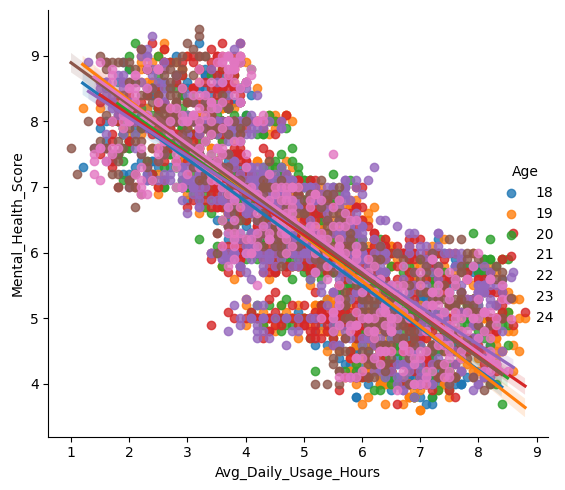

In [12]:
sns.lmplot(x='Avg_Daily_Usage_Hours', y='Mental_Health_Score', hue='Age',data=df)
plt.tight_layout()
plt.show()

## **4.5 — Sleep Hours vs Mental Health Score**
Sleep is one of the most commonly cited mental health factors — does the data back that up?

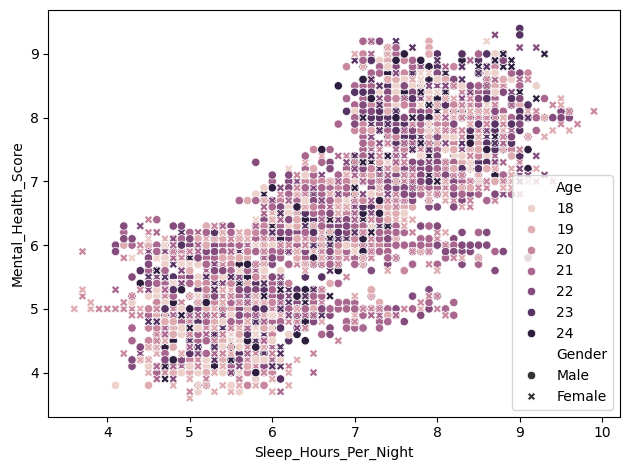

In [13]:
sns.scatterplot(x=df['Sleep_Hours_Per_Night'] , y = df['Mental_Health_Score'], hue = df['Age'] , style=df['Gender'])
plt.tight_layout()
plt.show()

### **4.6 — Most Used Platform (count)**
A quick look at which platforms are most common in our dataset.

In [14]:
df.head()


,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [15]:
df['Most_Used_Platform'].unique()

array(['Facebook', 'LinkedIn', 'Instagram', 'Snapchat', 'Twitter',
       'YouTube', 'TikTok', 'LINE', 'KakaoTalk', 'VKontakte', 'WhatsApp',
       'WeChat'], dtype=object)

In [16]:
df['Most_Used_Platform'].value_counts()

,count
Most_Used_Platform,
Instagram,1130
TikTok,918
Facebook,719
LinkedIn,523
YouTube,491
Twitter,462
Snapchat,420
WhatsApp,175
LINE,50


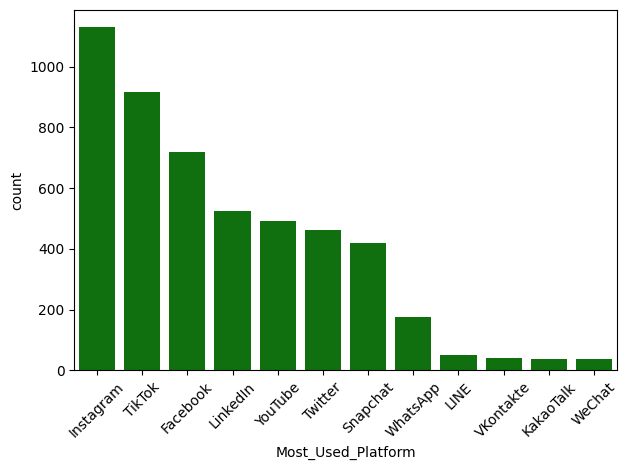

In [17]:
sns.countplot(data=df, x='Most_Used_Platform', color="green", order=df['Most_Used_Platform'].value_counts().index)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Checking outliers


In [18]:
num_cols=df.select_dtypes(include='number')
Q1=num_cols.quantile(0.25)
Q3=num_cols.quantile(0.75)
IQR=Q3-Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers=(num_cols<lower_bound)|(num_cols>upper_bound)
print(outliers.sum())

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


### **5. Data Cleaning**

Two real issues to fix here — everything else in this dataset is already clean, so we don't manufacture cleaning steps that aren't needed.

In [19]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [20]:
df=df.drop_duplicates()

#Converting negative or unrealitstic value to realistic value'
df['Physical_Activity_Hours']=df['Physical_Activity_Hours'].clip(lower=0)

In [21]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.751160,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.667282,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


📌 Why clip(lower=0) and not dropping the row: the rest of that student's data (age, study hours, stress level, etc.) is still valid and useful — throwing away the whole row over one bad value wastes good data. Clipping caps the impossible value at the nearest realistic one (0 hours) without discarding everything else about that student.

We're not dropping any columns either — every column here has a plausible reason to matter for predicting mental health, and we already confirmed none of them are empty or constant.

### **6. Skewness**
What skewness is: a measure of how lopsided a numeric column's distribution is. A value near 0 means roughly symmetric (bell-shaped); a large positive or negative value means the data leans heavily to one side, with a long tail.

**Why it matters**: models like Linear Regression assume features are roughly well-behaved. A heavily skewed column (think: a long tail of extreme values) can quietly drag the model's predictions in that direction. Tree-based models like Random Forest don't care about skew — but since we're also training a Linear Regression baseline, it's worth fixing.

In [22]:
num_cols
num_cols.skew()

,0
Age,0.155325
Avg_Daily_Usage_Hours,0.005606
Daily_Unlocks,0.002351
Study_Hours,0.435819
Physical_Activity_Hours,0.039971
Sleep_Hours_Per_Night,0.124050
Mental_Health_Score,0.206567


# **7. Feature Engineering**
One meaningful engineered feature here: grouping Country.



*   Country has 111 unique values in this dataset — one-hot encoding that directly
would add 110+ mostly-empty columns, which hurts the model far more than it helps (this is called high cardinality).
*   Dropping Country entirely throws away real signal — a student's country genuinely correlates with things like internet access, culture, and sleep norms.


The fix: keep the top 10 most frequent countries as their own category, and bucket everything else into "Other". We keep the signal that matters and lose the noise that doesn't.

In [23]:
df['Country'].value_counts()

,count
Country,
Other,1879
India,389
USA,354
Canada,230
Australia,198
...,...
Armenia,1
Bosnia,1
Kuwait,1


In [24]:
top_countries=df['Country'].value_counts().index[:10].tolist()
top_countries

['Other',
 'India',
 'USA',
 'Canada',
 'Australia',
 'UK',
 'Germany',
 'Mexico',
 'Turkey',
 'France']

In [25]:
def group_countries(Country):
  if Country in top_countries:
    return Country
  else:
    return 'Other'

In [26]:
df['Grouped_country'] = df['Country'].apply(group_countries)
df['Grouped_country'].value_counts()

,count
Grouped_country,
Other,3231
India,389
USA,354
Canada,230
Australia,198
UK,185
Germany,136
Mexico,94
Turkey,94


📌 Result: we went from 111 raw categories down to 11 manageable ones (10 countries + "Other"). This is exactly the kind of decision that separates a project that "just ran pd.get_dummies()" from one that actually thought about the data.

# **8. Train-Test Split**
Why we split: we need data the model has never seen to honestly check how well it generalizes. If we evaluate on the same data we trained on, the model can just "memorize" the answers and look artificially good.

Common ratios: 80/20 or 70/30 are both standard. We'll use an 80/20 split here — with 5,000 rows, that still leaves 1,000 rows for a solid, reliable test.

We split before fitting any preprocessing — this is the single most common beginner mistake (called data leakage), and we'll avoid it by fitting everything only on the training set.

In [27]:
from sklearn.model_selection import train_test_split

skewd_col= ['Study_Hours']
other_numeric_cols = ["Age", "Avg_Daily_Usage_Hours", "Daily_Unlocks","Physical_Activity_Hours",
                      "Sleep_Hours_Per_Night"]
ordinal_col        = ['Stress_Level']
normal_col         = ["Gender", "Academic_Level", "Most_Used_Platform", "Purpose_Of_Use", "Grouped_country"]

feature_cols = skewd_col + other_numeric_cols + ordinal_col + normal_col
target_col = "Mental_Health_Score"

X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

Preprocessing using ColumnTransformer
Our columns need different treatment:


*   Study_Hours (the skewed one) → impute → log1p transform → scale
*   The other numeric columns → impute → scale (no skew to fix)
*   Stress_Level → impute → OrdinalEncoder with an explicit order
*   The nominal columns → impute → OneHotEncoder

We include a SimpleImputer in every branch even though this dataset has zero missing values right now — it's a safety net. Real-world data (and our future API's incoming requests) won't always be this clean, and a pipeline that assumes "no missing values ever" is a pipeline that breaks in production.

ColumnTransformer glues all of this into one object that applies the right transformation to the right column type in a single .fit() / .transform() call — no manual column-by-column juggling.

## **Build a Pipeline**
Why Pipeline matters: a Pipeline chains preprocessing and the model into a single object. Calling .fit() once does both steps in the correct order, and calling .predict() on brand-new raw data automatically applies the exact same preprocessing that was used during training — no risk of forgetting a step or applying it inconsistently.

Why companies prefer this: when this model gets deployed (which we're doing in Part 2 with FastAPI), the API doesn't need to know anything about scaling, encoding, or log transforms — it just loads one saved pipeline object and calls .predict() on raw input. That's a huge reduction in what can go wrong in production.

We'll build two pipelines below — one per model — so we can fairly compare them.

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline

# 1) skewed
skew_pipeline = Pipeline(steps=[
    ('log_transform', FunctionTransformer(np.log1p)),
    ('scale', StandardScaler())
])

# 2) scaling
numeric_pipeline = Pipeline(steps=[
    ('scale', StandardScaler())
])

# 3) ordinal encoder
ordinal_pipeline = Pipeline(steps=[
    ("ordinal_encoder", OrdinalEncoder(categories=[['Low', 'Medium', 'High', 'Very High']]))
])

# 4) Nominal Features
nominal_pipeline = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ('skew', skew_pipeline, skewd_col),
    ('scale', numeric_pipeline, other_numeric_cols),
    ('ordinal', ordinal_pipeline, ordinal_col),
    ('ohe', nominal_pipeline, normal_col)
])

### 12. Model Building
We're comparing two models here because the comparison itself teaches something useful — a plain Linear Regression baseline versus a Random Forest, which can capture the non-linear patterns we spotted back in EDA (section 4.4).

12.1 — Baseline: Linear Regression

In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, accuracy_score, mean_absolute_error, mean_squared_error

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ("lr", LinearRegression())
])

lr_pipeline.fit(X_train, y_train)
lr_pred = lr_pipeline.predict(X_test)
lr_preds_train = lr_pipeline.predict(X_train)

lr_r2_testing  = r2_score(y_test, lr_pred)
lr_r2_training = r2_score(y_train, lr_preds_train)
lr_mae         = mean_absolute_error(y_test, lr_pred)

print(f"R2 Score: {r2_score(y_test, lr_pred)}")
print(f"mae Score: {mean_absolute_error(y_test, lr_pred)}")
print(f"mse Score: {mean_squared_error(y_test, lr_pred)}")

R2 Score: 0.7397944617433021
mae Score: 0.5361775634720181
mse Score: 0.45701905273487986


12.2 — Random Forest (default settings)


In [34]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ("rf", RandomForestRegressor(random_state = 42))
])

rf_pipeline.fit(X_train, y_train)
rf_pred = rf_pipeline.predict(X_test)
rf_preds_training = rf_pipeline.predict(X_train)

rf_r2_testing  = r2_score(y_test, rf_pred)
rf_r2_training = r2_score(y_train, rf_preds_training)
rf_mae         = mean_absolute_error(y_test, rf_pred)


print(f"R2 Score: {r2_score(y_test, rf_pred)}")
print(f"mae Score: {mean_absolute_error(y_test, rf_pred)}")
print(f"mse Score: {mean_squared_error(y_test, rf_pred)}")

R2 Score: 0.8775888638668996
mae Score: 0.34722113333333343
mse Score: 0.21500011819333337


# **12.3 — Hyperparameter Tuning the Random Forest**

When tuning a Pipeline, each parameter needs to be prefixed with the step name (regressor__) so RandomizedSearchCV knows which part of the pipeline it belongs to. We use RandomizedSearchCV instead of a full grid search — it samples a fixed number of combinations instead of testing every single one, which is far faster while still finding a strong set of parameters.


In [35]:
from sklearn.model_selection import RandomizedSearchCV

param_grid={
    "rf__n_estimators":[100,200,300],
    "rf__max_depth":[15,20,25],
    "rf__min_samples_split":[2,5,10],
    "rf__min_samples_leaf":[2,4,6]
}

random_search=RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=15,
    cv=5,
    random_state=42,
    n_jobs =-1
    )

random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('skew',
                                                                               Pipeline(steps=[('log_transform',
                                                                                                FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                                               ('scale',
                                                                                                StandardScaler())]),
                                                                               ['Study_Hours']),
                                                                              ('scale',
                                                                               Pipeline(steps=[('scale',
                                                                                                StandardScaler())]),
                                                                               ['Age',
                                                                                'Avg_Daily_Usage_Hours',
                                                                                'Daily_Unlocks',
                                                                                'Physical_Activity_Hou...
                                                                                                OneHotEncoder(handle_unknown='ignore'))]),
                                                                               ['Gender',
                                                                                'Academic_Level',
                                                                                'Most_Used_Platform',
                                                                                'Purpose_Of_Use',
                                                                                'Grouped_country'])])),
                                             ('rf',
                                              RandomForestRegressor(random_state=42))]),
                   n_iter=15, n_jobs=-1,
                   param_distributions={'rf__max_depth': [15, 20, 25],
                                        'rf__min_samples_leaf': [2, 4, 6],
                                        'rf__min_samples_split': [2, 5, 10],
                                        'rf__n_estimators': [100, 200, 300]},
                   random_state=42)

In [36]:
random_search.best_params_

{'rf__n_estimators': 200,
 'rf__min_samples_split': 2,
 'rf__min_samples_leaf': 2,
 'rf__max_depth': 20}

In [41]:
rf_best_pipeline  = random_search.best_estimator_
rf_best_preditics = rf_best_pipeline.predict(X_test)

print(f"R2 Score for random forest after hyperparameter tuning {r2_score(y_test, rf_best_preditics)}")
print(f"MAE Score for random forest after hyperparameter tuning {mean_absolute_error(y_test, rf_best_preditics)}")

R2 Score for random forest after hyperparameter tuning 0.8711687556014749
MAE Score for random forest after hyperparameter tuning 0.3577934262913398


### **13. Model Evaluation**
Metrics, explained simply:



*  R² Score — how much of the variation in mental health scores our model explains, from 0 (useless) to 1 (perfect). 0.85 means the model explains 85% of the pattern.
* MAE (Mean Absolute Error) — on average, how far off our prediction is, in the original units (score points). Easy to explain to a non-technical person.
*  RMSE (Root Mean Squared Error) — similar to MAE, but penalizes big mistakes more heavily. Useful for spotting whether a model makes a few very wrong predictions.
*  Cross-validation R² (from tuning, above) tells us how good the model is across many different train/validation splits — the real, honest test is still the untouched test set below.

In [43]:
from sklearn.metrics import mean_squared_error

# Calculate RMSE for Linear Regression
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))

# Calculate RMSE for default Random Forest
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

# Calculate RMSE for tuned Random Forest
rf_tuned_preds          = random_search.best_estimator_.predict(X_test)
rf_tuned_rmse           = np.sqrt(mean_squared_error(y_test, rf_tuned_preds))
rf_tuned_training_preds = random_search.best_estimator_.predict(X_train)
r2_tuned_training       = r2_score(y_train, rf_tuned_training_preds)
rf_tuned_mae            = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_r2             = r2_score(y_test, rf_tuned_preds)


# Create a DataFrame to consolidate results
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest (default)', 'Random Forest (tuned)'],
    'R2': [lr_r2_testing, rf_r2_testing, rf_tuned_r2],
    'Training R2': [lr_r2_training, rf_r2_training, r2_tuned_training],
    'MAE': [lr_mae, rf_mae, rf_tuned_mae],
    'RMSE': [lr_rmse, rf_rmse, rf_tuned_rmse]
})

print(results)

                     Model        R2  Training R2       MAE      RMSE
0        Linear Regression  0.739794     0.723677  0.536178  0.676032
1  Random Forest (default)  0.877589     0.980829  0.347221  0.463681
2    Random Forest (tuned)  0.871169     0.967278  0.357793  0.475685


**14. Save the Model**

We save the entire pipeline — preprocessing and model together — as a single file, not just the raw model. Why: if we only saved the Random Forest object, our FastAPI backend would need to manually recreate every encoding and scaling step by hand at prediction time, which is fragile and easy to get wrong. Saving the full pipeline means the backend just loads one file and calls .predict() on raw input — the pipeline handles everything internally, exactly the same way it did during training.

In [44]:

import joblib
joblib.dump(rf_pipeline, 'Mental_Health_Model.pkl')

['Mental_Health_Model.pkl']